In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split

# 1. Muat dataset mentah
raw_df = pd.read_csv('car_price.csv')

# 2. Bagi data: 80% train (2.000 data) dan 20% test (500 data)
train_df, test_df = train_test_split(raw_df, test_size=0.2, random_state=42)

# 3. Pisahkan label 'Price' dari data test agar menyerupai format ujian/kompetisi
test_features = test_df.drop(columns=['Price'])

# 4. Simpan kunci jawaban test untuk verifikasi performa di tahap akhir nanti
test_df[['Car ID', 'Price']].to_csv('test_ground_truth.csv', index=False)

# 5. Simpan file train.csv dan test.csv
train_df.to_csv('train.csv', index=False)
test_features.to_csv('test.csv', index=False)

print(f"Data train tersimpan: {train_df.shape[0]} baris, {train_df.shape[1]} kolom")
print(f"Data test tersimpan : {test_features.shape[0]} baris, {test_features.shape[1]} kolom (tanpa Price)")

Data train tersimpan: 2000 baris, 10 kolom
Data test tersimpan : 500 baris, 9 kolom (tanpa Price)


In [3]:
import pandas as pd

# Muat data test
test = pd.read_csv("test.csv")
print("=== 5 Data Pertama Test ===")
display(test.head())

# Muat data train
train = pd.read_csv("train.csv")
print("\n=== 5 Data Pertama Train ===")
display(train.head())

=== 5 Data Pertama Test ===


,Car ID,Brand,Year,Engine Size,Fuel Type,Transmission,Mileage,Condition,Model
0,1448,Honda,2010,3.0,Diesel,Manual,211864,Like New,Fit
1,1115,Tesla,2020,4.4,Hybrid,Manual,18781,Like New,Model 3
2,1065,Toyota,2013,4.3,Diesel,Manual,55547,Like New,RAV4
3,2288,Toyota,2006,3.0,Hybrid,Automatic,196914,Used,Camry
4,1538,BMW,2016,5.5,Petrol,Automatic,67764,Like New,5 Series



=== 5 Data Pertama Train ===


,Car ID,Brand,Year,Engine Size,Fuel Type,Transmission,Mileage,Condition,Price,Model
0,2056,Mercedes,2005,3.4,Electric,Automatic,73401,New,97600.01,C-Class
1,1962,BMW,2004,1.6,Diesel,Manual,252234,New,9212.70,5 Series
2,1865,Tesla,2002,5.8,Diesel,Manual,89882,Like New,89909.81,Model X
3,2327,Mercedes,2000,4.6,Diesel,Manual,275333,New,38235.97,GLC
4,462,Honda,2010,3.2,Diesel,Manual,41190,Like New,77675.22,CR-V


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Memuat data train hasil split dataset mobil
train = pd.read_csv("train.csv")

# 1. Menampilkan ringkasan informasi dan tipe data
train.info()

# 2. Menampilkan statistik deskriptif untuk fitur numerik dan kategorikal
train.describe(include="all")

# 3. Memeriksa jumlah nilai yang hilang di setiap kolom
missing_values = train.isnull().sum()
print("Fitur dengan missing value:")
print(missing_values[missing_values > 0])

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Car ID        2000 non-null   int64  
 1   Brand         2000 non-null   str    
 2   Year          2000 non-null   int64  
 3   Engine Size   2000 non-null   float64
 4   Fuel Type     2000 non-null   str    
 5   Transmission  2000 non-null   str    
 6   Mileage       2000 non-null   int64  
 7   Condition     2000 non-null   str    
 8   Price         2000 non-null   float64
 9   Model         2000 non-null   str    
dtypes: float64(2), int64(3), str(5)
memory usage: 156.4 KB
Fitur dengan missing value:
Series([], dtype: int64)


In [5]:
# Ambang batas 75% dari total baris data train mobil
threshold = 0.75 * len(train)

less = missing_values[missing_values < threshold].index
over = missing_values[missing_values >= threshold].index

# 1. Mengisi missing value numerik dengan median
numeric_features = train[less].select_dtypes(include=['number']).columns
train[numeric_features] = train[numeric_features].fillna(train[numeric_features].median())

# 2. Mengisi missing value kategorikal dengan modus (nilai terbanyak)
kategorical_features = train[less].select_dtypes(include=['object']).columns
for column in kategorical_features:
    if train[column].isnull().sum() > 0:
        train[column] = train[column].fillna(train[column].mode()[0])

# 3. Menghapus kolom dengan missing value > 75%
df = train.drop(columns=over)

# 4. Hapus kolom 'Car ID' karena hanya nomor identitas (tidak prediktif)
if 'Car ID' in df.columns:
    df = df.drop(columns=['Car ID'])

# Verifikasi ulang missing value
missing_values_check = df.isnull().sum()
print("Sisa missing value setelah penanganan:")
print(missing_values_check[missing_values_check > 0])

Sisa missing value setelah penanganan:
Series([], dtype: int64)


C:\Users\gabri\AppData\Local\Temp\ipykernel_3448\409989594.py:12: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  kategorical_features = train[less].select_dtypes(include=['object']).columns


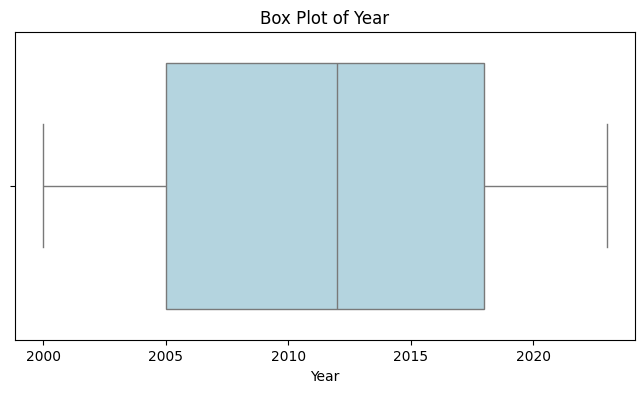

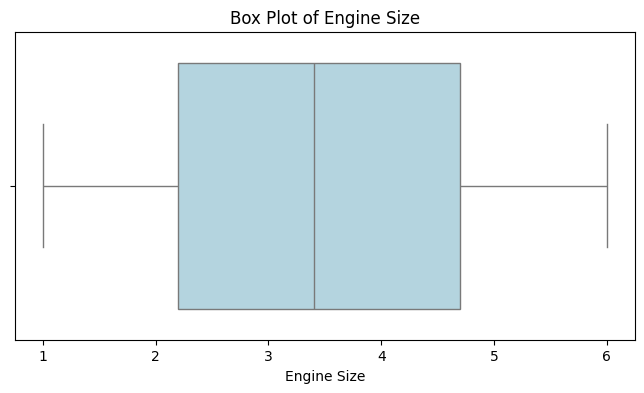

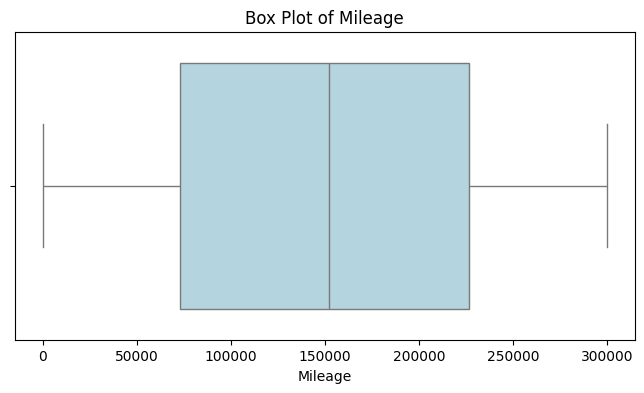

Dimensi data setelah penanganan outlier: (2000, 9)


In [6]:
# Tentukan fitur numerik yang akan diperiksa
numeric_features = [c for c in df.select_dtypes(include=['number']).columns if c != 'Price']

# 1. Visualisasi Box Plot untuk setiap fitur numerik
for feature in numeric_features:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df[feature], color='lightblue')
    plt.title(f'Box Plot of {feature}')
    plt.show()

# 2. Menghitung Q1, Q3, dan IQR
Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)
IQR = Q3 - Q1

# 3. Filter dataframe untuk menyimpan baris yang tidak mengandung outlier
condition = ~((df[numeric_features] < (Q1 - 1.5 * IQR)) | (df[numeric_features] > (Q3 + 1.5 * IQR))).any(axis=1)
df_filtered_numeric = df.loc[condition, numeric_features]

# 4. Menggabungkan kembali dengan kolom kategorikal dan target
non_numeric_cols = [c for c in df.columns if c not in numeric_features]
df = pd.concat([df_filtered_numeric, df.loc[condition, non_numeric_cols]], axis=1)

print(f"Dimensi data setelah penanganan outlier: {df.shape}")

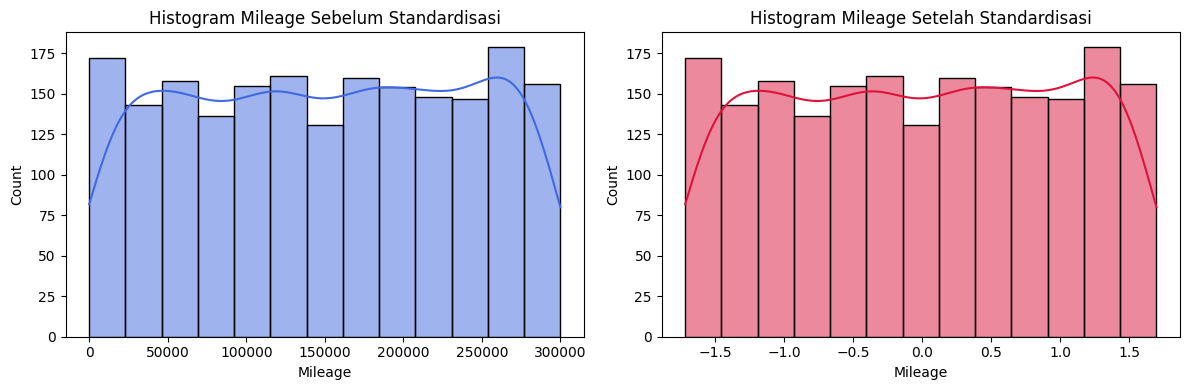

In [7]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# 1. Visualisasi perbandingan fitur 'Mileage' sebelum standardisasi
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.histplot(train['Mileage'], kde=True, color='royalblue')
plt.title("Histogram Mileage Sebelum Standardisasi")

# 2. Terapkan StandardScaler pada fitur numerik input
df[numeric_features] = scaler.fit_transform(df[numeric_features])

# 3. Visualisasi setelah standardisasi
plt.subplot(1, 2, 2)
sns.histplot(df['Mileage'], kde=True, color='crimson')
plt.title("Histogram Mileage Setelah Standardisasi")
plt.tight_layout()
plt.show()

In [8]:
# 1. Mengidentifikasi baris duplikat
duplicates = df.duplicated()
print(f"Jumlah baris duplikat: {duplicates.sum()}")

# 2. Menghapus jika ditemukan duplikat
if duplicates.sum() > 0:
    df = df.drop_duplicates()
    print("DataFrame setelah menghapus duplikat:")
    print(df.shape)
else:
    print("Tidak ditemukan baris duplikat.")

Jumlah baris duplikat: 0
Tidak ditemukan baris duplikat.


In [9]:
# Mengidentifikasi fitur bertipe kategorikal
category_features = df.select_dtypes(include=['object']).columns
print("Fitur kategorikal:", category_features.tolist())

# --- Opsi A: One-Hot Encoding ---
df_one_hot = pd.get_dummies(df, columns=category_features)
print(f"Bentuk setelah One-Hot Encoding: {df_one_hot.shape}")
display(df_one_hot.head(3))

# --- Opsi B: Label Encoding (Sesuai pendekatan akhir pada modul latihan) ---
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
df_lencoder = df.copy()

for col in category_features:
    df_lencoder[col] = label_encoder.fit_transform(df_lencoder[col])

print(f"\nBentuk setelah Label Encoding: {df_lencoder.shape}")
display(df_lencoder.head())

Fitur kategorikal: ['Brand', 'Fuel Type', 'Transmission', 'Condition', 'Model']
Bentuk setelah One-Hot Encoding: (2000, 48)


C:\Users\gabri\AppData\Local\Temp\ipykernel_3448\1467713621.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  category_features = df.select_dtypes(include=['object']).columns


,Year,Engine Size,Mileage,Price,Brand_Audi,Brand_BMW,Brand_Ford,Brand_Honda,Brand_Mercedes,Brand_Tesla,...,Model_Model S,Model_Model X,Model_Model Y,Model_Mustang,Model_Prius,Model_Q5,Model_Q7,Model_RAV4,Model_X3,Model_X5
0,-0.940027,-0.040969,-0.883145,97600.01,False,False,False,False,True,False,...,False,False,False,False,False,False,False,False,False,False
1,-1.083685,-1.302642,1.153363,9212.70,False,True,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,-1.371001,1.641261,-0.695464,89909.81,False,False,False,False,False,True,...,False,True,False,False,False,False,False,False,False,False



Bentuk setelah Label Encoding: (2000, 9)


,Year,Engine Size,Mileage,Brand,Fuel Type,Transmission,Condition,Price,Model
0,-0.940027,-0.040969,-0.883145,4,1,0,1,97600.01,5
1,-1.083685,-1.302642,1.153363,1,0,1,1,9212.70,1
2,-1.371001,1.641261,-0.695464,5,0,1,0,89909.81,19
3,-1.658318,0.800146,1.416409,4,0,1,1,38235.97,16
4,-0.221736,-0.181155,-1.249957,3,0,1,0,77675.22,6


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Menampilkan 5 baris pertama data hasil transformasi
display(df_lencoder.head())

# Menghitung jumlah dan persentase missing values di setiap kolom
missing_values = df_lencoder.isnull().sum()
missing_percentage = (missing_values / len(df_lencoder)) * 100

missing_data = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage': missing_percentage
}).sort_values(by='Missing Values', ascending=False)

# Menampilkan kolom jika masih terdapat missing values
display(missing_data[missing_data['Missing Values'] > 0])

,Year,Engine Size,Mileage,Brand,Fuel Type,Transmission,Condition,Price,Model
0,-0.940027,-0.040969,-0.883145,4,1,0,1,97600.01,5
1,-1.083685,-1.302642,1.153363,1,0,1,1,9212.70,1
2,-1.371001,1.641261,-0.695464,5,0,1,0,89909.81,19
3,-1.658318,0.800146,1.416409,4,0,1,1,38235.97,16
4,-0.221736,-0.181155,-1.249957,3,0,1,0,77675.22,6


,Missing Values,Percentage


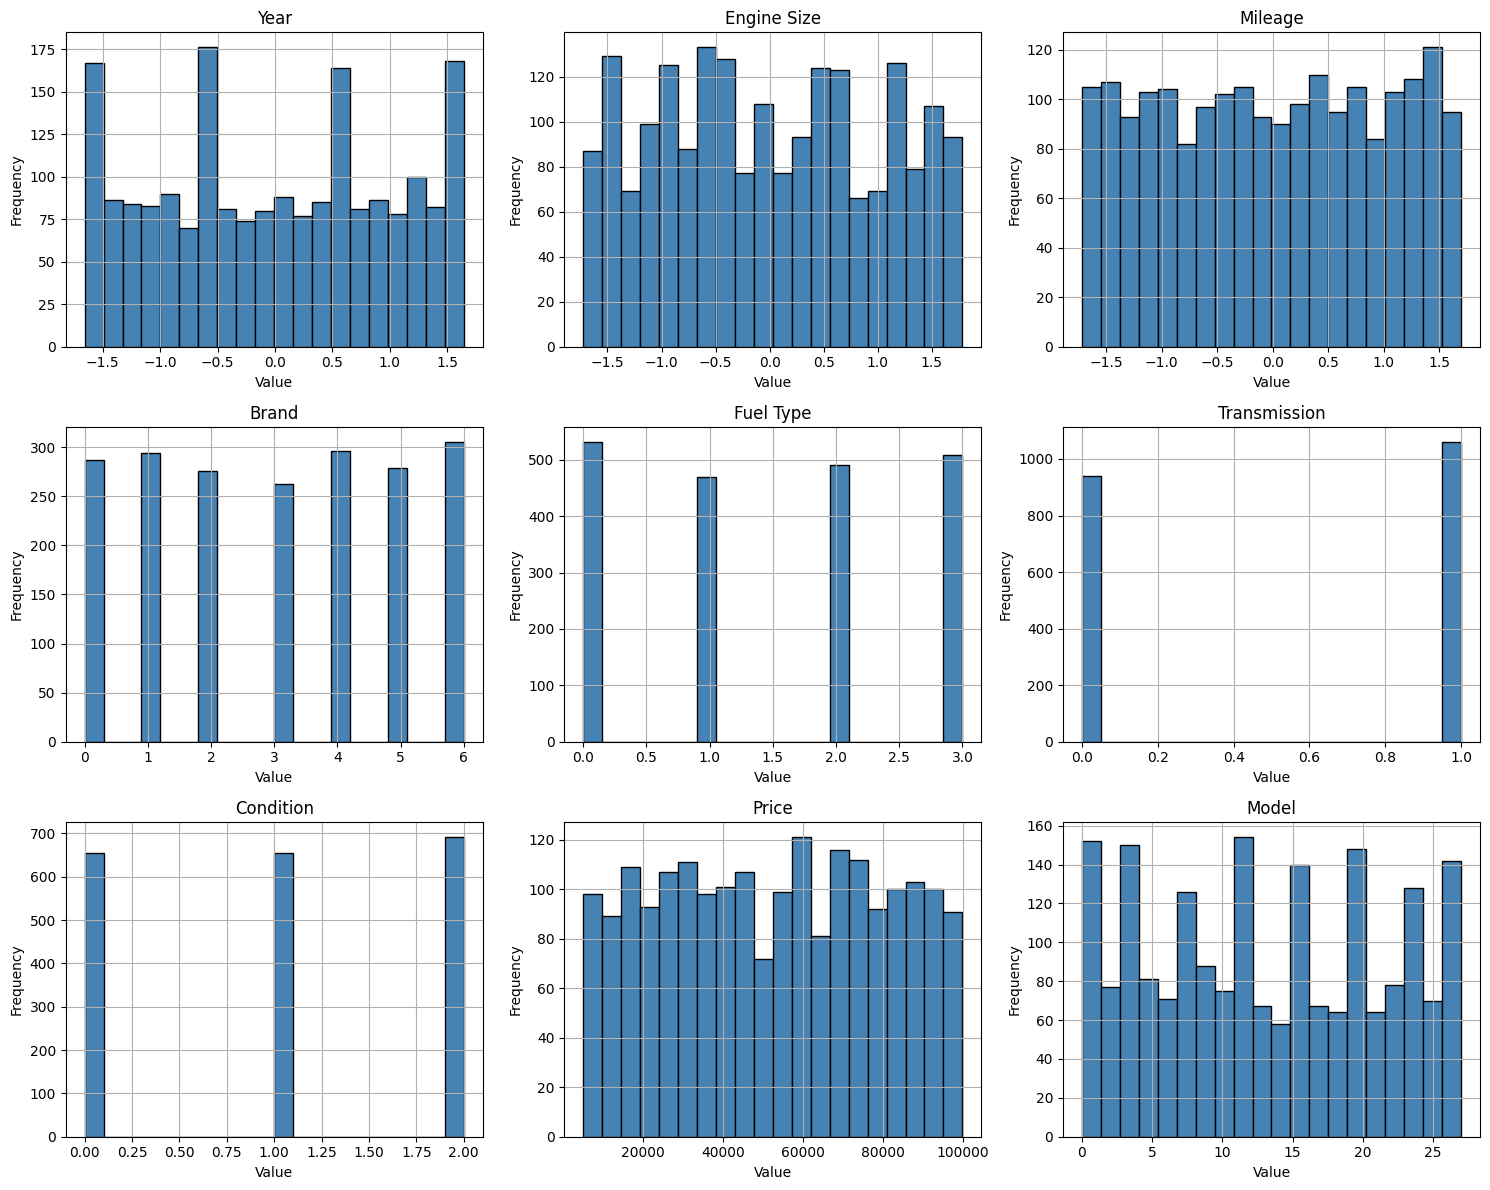

In [11]:
# Menghitung jumlah variabel
num_vars = df_lencoder.shape[1]

# Menentukan jumlah baris dan kolom untuk grid subplot
n_cols = 3  # Disesuaikan menjadi 3 kolom agar visualisasi 9 fitur lebih proporsional
n_rows = -(-num_vars // n_cols)

# Membuat subplot
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, n_rows * 4))
axes = axes.flatten()

# Plot setiap variabel
for i, column in enumerate(df_lencoder.columns):
    df_lencoder[column].hist(ax=axes[i], bins=20, edgecolor='black', color='steelblue')
    axes[i].set_title(column)
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')

# Menghapus subplot sisa jika ada
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

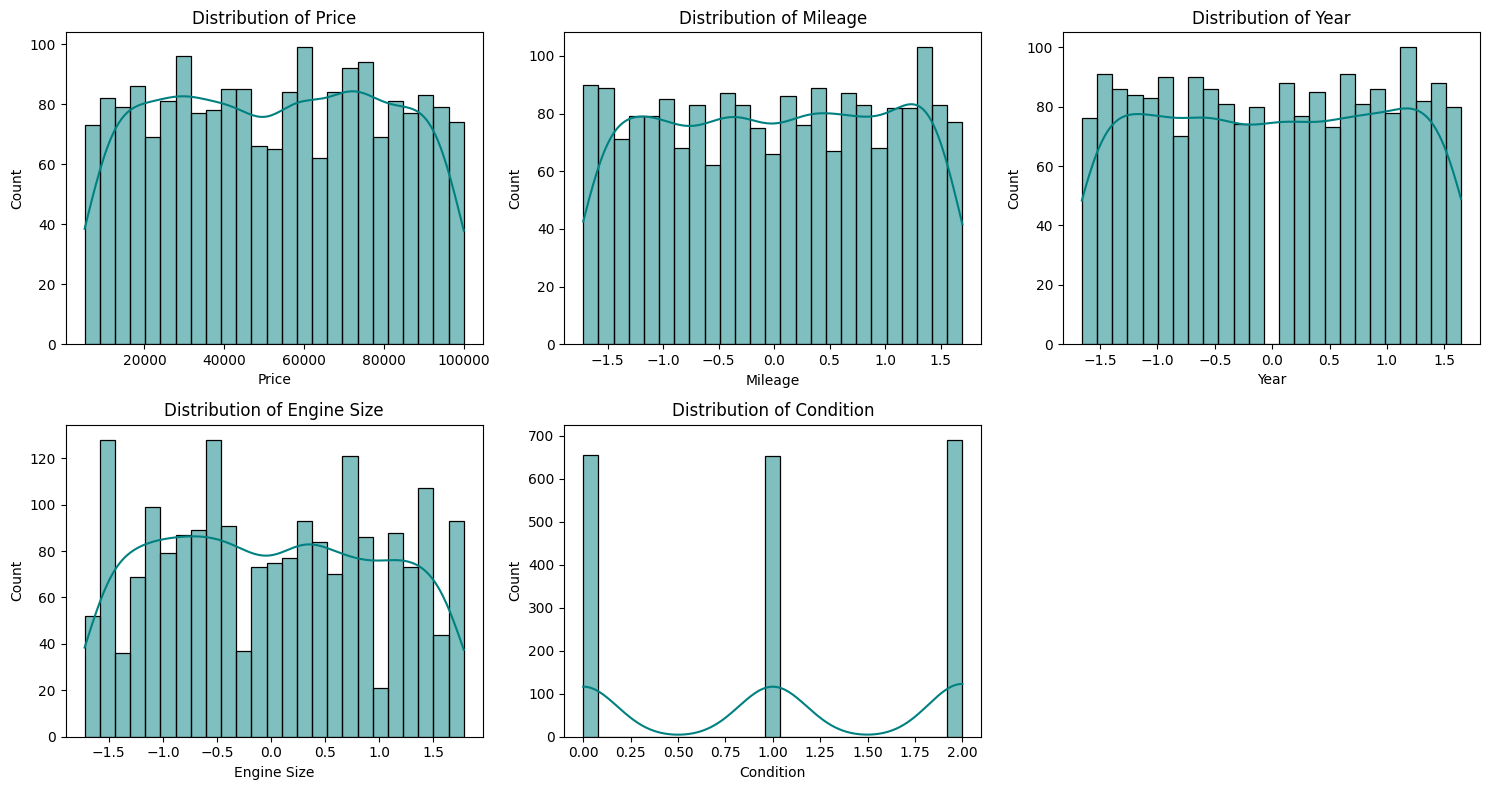

In [12]:
# Memilih kolom penting untuk diamati lebih detail
columns_to_plot = ['Price', 'Mileage', 'Year', 'Engine Size', 'Condition']

plt.figure(figsize=(15, 8))
for i, column in enumerate(columns_to_plot, 1):
    plt.subplot(2, 3, i)
    sns.histplot(df_lencoder[column], kde=True, bins=25, color='teal')
    plt.title(f'Distribution of {column}')

plt.tight_layout()
plt.show()

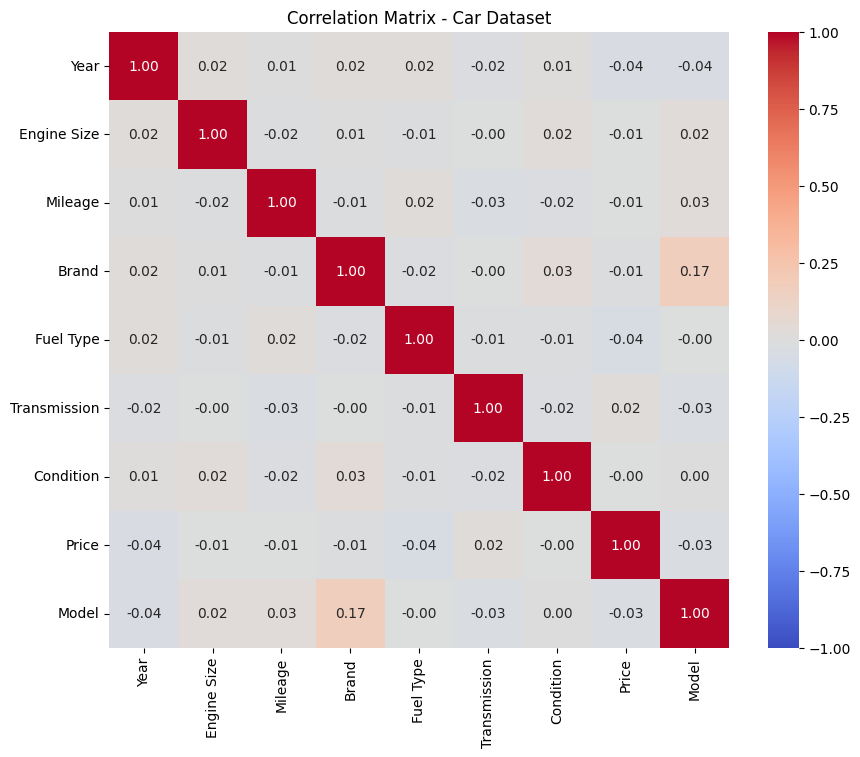

In [13]:
plt.figure(figsize=(10, 8))
correlation_matrix = df_lencoder.corr()

# Visualisasi matriks korelasi dengan anotasi angka
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix - Car Dataset')
plt.show()

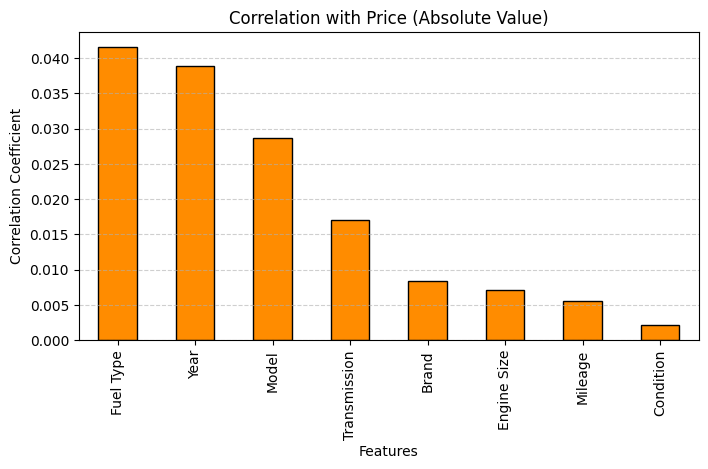

,Correlation with Price
Fuel Type,-0.041605
Year,-0.038896
Model,-0.028637
Transmission,0.017061
Brand,-0.008408
Engine Size,-0.007181
Mileage,-0.005499
Condition,-0.002206


In [14]:
# Menghitung korelasi antara target Price dan seluruh fitur lainnya
target_corr = df_lencoder.corr()['Price'].drop('Price')

# Mengurutkan korelasi berdasarkan nilai absolut terbesar
target_corr_sorted = target_corr.abs().sort_values(ascending=False)

plt.figure(figsize=(8, 4))
target_corr_sorted.plot(kind='bar', color='darkorange', edgecolor='black')
plt.title('Correlation with Price (Absolute Value)')
plt.xlabel('Features')
plt.ylabel('Correlation Coefficient')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

# Menampilkan nilai koefisien korelasi secara detail
display(pd.DataFrame({'Correlation with Price': target_corr.loc[target_corr_sorted.index]}))

In [15]:
# Memisahkan fitur (X) dan target (y)
X = df_lencoder.drop(columns=['Price'])  
y = df_lencoder['Price']

print("Dimensi fitur X :", X.shape)
print("Dimensi target y:", y.shape)

Dimensi fitur X : (2000, 8)
Dimensi target y: (2000,)


In [16]:
from sklearn.model_selection import train_test_split

# Membagi dataset menjadi training dan testing set
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

In [17]:
# Menghitung panjang/jumlah data 
print("Jumlah data total :", len(X))

# Menghitung panjang/jumlah data pada x_train (80%)
print("Jumlah data latih :", len(x_train))

# Menghitung panjang/jumlah data pada x_test (20%)
print("Jumlah data test  :", len(x_test))

Jumlah data total : 2000
Jumlah data latih : 1600
Jumlah data test  : 400


In [18]:
# 1. Melatih model 1 dengan algoritma Least Angle Regression
from sklearn import linear_model
lars = linear_model.Lars(n_nonzero_coefs=1).fit(x_train, y_train)

# 2. Melatih model 2 dengan algoritma Linear Regression
from sklearn.linear_model import LinearRegression
LR = LinearRegression().fit(x_train, y_train)

# 3. Melatih model 3 dengan algoritma Gradient Boosting Regressor
from sklearn.ensemble import GradientBoostingRegressor
GBR = GradientBoostingRegressor(random_state=184)
GBR.fit(x_train, y_train)

,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'The function to measure the quality of a split. Supported criteria are""friedman_mse"" for the mean squared error with improvement score byFriedman, ""squared_error"" for mean squared error. The default value of""friedman_mse"" is generally the best as it can provide a betterapproximation in some cases... versionadded:: 0.18",'friedman_mse'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft 

In [19]:
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Evaluasi pada model LARS
pred_lars = lars.predict(x_test)
mae_lars = mean_absolute_error(y_test, pred_lars)
mse_lars = mean_squared_error(y_test, pred_lars)
r2_lars = r2_score(y_test, pred_lars)

# Membuat DataFrame untuk menampung hasil evaluasi
data = {
    'MAE': [mae_lars],
    'MSE': [mse_lars],
    'R2': [r2_lars]
}
df_results = pd.DataFrame(data, index=['Lars'])

# Evaluasi pada model Linear Regression
pred_LR = LR.predict(x_test)
mae_LR = mean_absolute_error(y_test, pred_LR)
mse_LR = mean_squared_error(y_test, pred_LR)
r2_LR = r2_score(y_test, pred_LR)

df_results.loc['Linear Regression'] = [mae_LR, mse_LR, r2_LR]

# Evaluasi pada model Gradient Boosting Regressor
pred_GBR = GBR.predict(x_test)
mae_GBR = mean_absolute_error(y_test, pred_GBR)
mse_GBR = mean_squared_error(y_test, pred_GBR)
r2_GBR = r2_score(y_test, pred_GBR)

df_results.loc['GradientBoostingRegressor'] = [mae_GBR, mse_GBR, r2_GBR]

# Menampilkan tabel perbandingan performa
display(df_results)

,MAE,MSE,R2
Lars,23517.210894,7.267552e+08,-0.002683
Linear Regression,23553.265297,7.296265e+08,-0.006644
GradientBoostingRegressor,23731.389451,7.498646e+08,-0.034566


In [20]:
# Opsi 1: Menggunakan joblib (Disarankan untuk model Scikit-Learn)
import joblib

joblib.dump(GBR, 'gbr_car_model.joblib')
print("Model GBR berhasil disimpan ke 'gbr_car_model.joblib'!")

Model GBR berhasil disimpan ke 'gbr_car_model.joblib'!


In [21]:
# Opsi 2: Menggunakan modul standar pickle
import pickle

with open('gbr_car_model.pkl', 'wb') as file:
    pickle.dump(GBR, file)
print("Model GBR berhasil disimpan ke 'gbr_car_model.pkl'!")

Model GBR berhasil disimpan ke 'gbr_car_model.pkl'!
